<a href="https://colab.research.google.com/github/imgeG/CYT-300-Group-1/blob/M5%266/CYT300_M6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from pathlib import Path
import json, time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import load_npz
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score, classification_report,
                             confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, StratifiedGroupKFold
from sklearn.naive_bayes import MultinomialNB
from sklearn.neural_network import MLPClassifier
from sklearn.svm import LinearSVC

from google.colab import drive
drive.mount('/content/drive')

SEED = 42
DATA_DIR = '/content/drive/MyDrive/CYT300/imge'     # where your notebook saved its files
OUT_DIR  = f'{DATA_DIR}/results'               # each model gets its own folder in here
Path(OUT_DIR).mkdir(parents=True, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
X = load_npz(f'{DATA_DIR}/X_train.npz').tocsr()      # features (sparse)
y = np.load(f'{DATA_DIR}/y_train.npy')               # labels: 0 = legit, 1 = phishing
groups = np.load(f'{DATA_DIR}/groups_train.npy', allow_pickle=True)   # sender of each row
assert len(groups) == len(y), "groups and y have different row counts"
prep  = joblib.load(f'{DATA_DIR}/preprocessing.joblib')
names = np.array(prep['full_feature_names'])         # name of every column

assert X.shape[0] == len(y), "X and y have different row counts"
assert X.shape[1] == len(names), "feature names don't match X columns"

# Optional external test set (made with prepare_test() in the preprocessing notebook)
test_ok = Path(f'{DATA_DIR}/X_test.npz').exists() and Path(f'{DATA_DIR}/y_test.npy').exists()
if test_ok:
    X_test = load_npz(f'{DATA_DIR}/X_test.npz').tocsr()
    y_test = np.load(f'{DATA_DIR}/y_test.npy')
    assert X_test.shape[1] == X.shape[1], "X_test has a different number of columns"

print("X:", X.shape, "| phishing ratio:", round(y.mean(), 3), "| external test set:", test_ok)


X: (51213, 7043) | phishing ratio: 0.582 | external test set: True


In [3]:
# Grouped split: no sender appears in both train and validation
tr_idx, val_idx = next(StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(X, y, groups))
X_tr, X_val = X[tr_idx], X[val_idx]
y_tr, y_val = y[tr_idx], y[val_idx]
g_tr = groups[tr_idx]                                 # senders in the training part (for tuning folds)
print("train:", X_tr.shape[0], "| validation:", X_val.shape[0],
      "| phishing ratio:", round(y_tr.mean(), 3), "/", round(y_val.mean(), 3))

train: 41044 | validation: 10169 | phishing ratio: 0.581 / 0.585


In [4]:
def get_scores(model, X_):
    """A continuous score per email (needed for ROC-AUC)."""
    if hasattr(model, 'predict_proba'):
        return model.predict_proba(X_)[:, 1]
    return model.decision_function(X_)

def evaluate(model, X_, y_):
    pred, score = model.predict(X_), get_scores(model, X_)
    tn, fp, fn, tp = confusion_matrix(y_, pred, labels=[0, 1]).ravel()
    return {'n': int(len(y_)),
            'accuracy': float((pred == y_).mean()),
            'precision': float(precision_score(y_, pred, zero_division=0)),
            'recall': float(recall_score(y_, pred, zero_division=0)),
            'f1': float(f1_score(y_, pred, zero_division=0)),
            'roc_auc': float(roc_auc_score(y_, score)),
            'pr_auc': float(average_precision_score(y_, score)),
            'false_positive_rate': float(fp / max(fp + tn, 1)),
            'false_negative_rate': float(fn / max(fn + tp, 1)),
            'confusion': {'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp)}}

def show_confusion(model, X_, y_, title, path):
    fig, ax = plt.subplots(figsize=(4.5, 4))
    ConfusionMatrixDisplay(confusion_matrix(y_, model.predict(X_)),
                           display_labels=['Legit', 'Phishing']).plot(ax=ax, colorbar=False, values_format='d')
    ax.set_title(title); fig.tight_layout(); fig.savefig(path, dpi=150); plt.show()

def top_features(model, k=30):
    """Most influential features, for models whose internals can be read."""
    if hasattr(model, 'coef_'):                       # logistic regression, linear SVM
        w = pd.Series(model.coef_.ravel(), index=names)
        return pd.concat([w.nlargest(k).to_frame('weight').assign(pushes_toward='phishing'),
                          w.nsmallest(k).to_frame('weight').assign(pushes_toward='legit')])
    if hasattr(model, 'feature_importances_'):        # random forest
        return pd.Series(model.feature_importances_, index=names).nlargest(2 * k).to_frame('importance')
    if hasattr(model, 'feature_log_prob_'):           # naive bayes: log-odds phishing vs legit
        w = pd.Series(model.feature_log_prob_[1] - model.feature_log_prob_[0], index=names)
        return pd.concat([w.nlargest(k).to_frame('log_odds').assign(pushes_toward='phishing'),
                          w.nsmallest(k).to_frame('log_odds').assign(pushes_toward='legit')])
    return None                                       # neural network: not directly readable

In [5]:
def run_model(name, estimator, space, n_iter, tune=True, search_jobs=-1, calibrate=False):
    out = Path(OUT_DIR) / name
    out.mkdir(parents=True, exist_ok=True)
    print(f"\n{'=' * 60}\n{name.upper()}\n{'=' * 60}")

    # 1) Tune on the training part only (3-fold cross-validation, optimising F1)
    t0 = time.time()
    if tune:
        search = RandomizedSearchCV(estimator, space, n_iter=n_iter, scoring='f1',
                                    cv=StratifiedGroupKFold(3, shuffle=True, random_state=SEED),
                                    random_state=SEED, n_jobs=search_jobs, verbose=1)
        search.fit(X_tr, y_tr, groups=g_tr)             # folds keep each sender on one side
        best, best_params, cv_f1 = search.best_estimator_, search.best_params_, float(search.best_score_)
        print("Best settings:", best_params, "| CV F1 =", round(cv_f1, 4))
    else:
        best, best_params, cv_f1 = estimator.fit(X_tr, y_tr), {}, None
    tune_sec = time.time() - t0

    # 2) Validation: compare training score with held-out score to spot overfitting
    train_m, val_m = evaluate(best, X_tr, y_tr), evaluate(best, X_val, y_val)
    print(f"Train F1 {train_m['f1']:.4f} | Validation F1 {val_m['f1']:.4f} | gap {train_m['f1'] - val_m['f1']:+.4f}")
    print(classification_report(y_val, best.predict(X_val), target_names=['Legit', 'Phishing'], digits=4))
    show_confusion(best, X_val, y_val, f'{name}: validation', out / 'confusion_validation.png')

    # 3) Refit on ALL training data with the chosen settings
    final = clone(best).fit(X, y)
    importance = top_features(final)                    # read importances before any wrapping
    if calibrate:                                       # gives the SVM probability outputs
        final = CalibratedClassifierCV(clone(best), cv=3).fit(X, y)

    # 4) Test on the external test set, if there is one
    test_m = None
    if test_ok:
        test_m = evaluate(final, X_test, y_test)
        print(f"TEST  F1 {test_m['f1']:.4f} | precision {test_m['precision']:.4f} | "
              f"recall {test_m['recall']:.4f} | ROC-AUC {test_m['roc_auc']:.4f}")
        show_confusion(final, X_test, y_test, f'{name}: test', out / 'confusion_test.png')

    # 5) Prediction speed (matters for a mail server)
    probe = X_val[:1000]
    t1 = time.time(); final.predict(probe)
    ms = (time.time() - t1) / probe.shape[0] * 1000

    # 6) Save everything for this model
    joblib.dump(final, out / 'model.joblib')
    if importance is not None:
        importance.to_csv(out / 'top_features.csv')
        display(importance.head(15))
    (out / 'metrics.json').write_text(json.dumps({
        'model': name,
        'best_params': {k: (list(v) if isinstance(v, tuple) else v) for k, v in best_params.items()},
        'cv_f1': cv_f1, 'train': train_m, 'validation': val_m, 'test': test_m,
        'tuning_seconds': round(tune_sec, 1), 'predict_ms_per_email': round(ms, 4)}, indent=2))
    print("Saved to", out)

In [6]:
# Ablation: does TF-IDF help, or do the numeric features do the work?
n_num = len(prep['features'])                     # numeric columns come first in X
subsets = {'numeric only': slice(0, n_num), 'text only': slice(n_num, None), 'combined': slice(None)}
for label, cols in subsets.items():
    m = LogisticRegression(max_iter=3000, class_weight='balanced', solver='liblinear', C=1)
    m.fit(X_tr[:, cols], y_tr)
    print(f"{label:13s} validation F1: {f1_score(y_val, m.predict(X_val[:, cols])):.4f}")

numeric only  validation F1: 0.9153
text only     validation F1: 0.9746
combined      validation F1: 0.9763



LOGREG
Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best settings: {'penalty': 'l2', 'C': 30} | CV F1 = 0.9855
Train F1 0.9999 | Validation F1 0.9771 | gap +0.0228
              precision    recall  f1-score   support

       Legit     0.9881    0.9458    0.9665      4224
    Phishing     0.9626    0.9919    0.9771      5945

    accuracy                         0.9728     10169
   macro avg     0.9754    0.9689    0.9718     10169
weighted avg     0.9732    0.9728    0.9727     10169



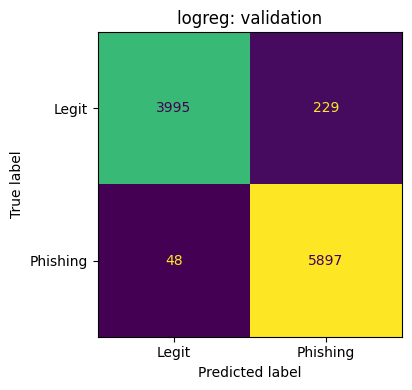

TEST  F1 0.8525 | precision 0.7929 | recall 0.9217 | ROC-AUC 0.9273


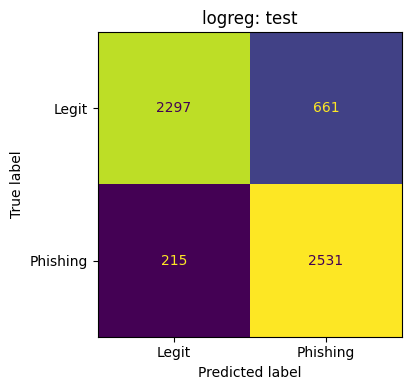

,weight,pushes_toward
body__love,9.354585,phishing
subj__com daily,9.035393,phishing
exclaim_count_log,8.633604,phishing
body__kindly,7.336645,phishing
body__lose,7.185462,phishing
body__payment,7.018817,phishing
body__click,6.394686,phishing
body__remove,6.277159,phishing
body__girl,6.241241,phishing
body__responsible,6.224952,phishing


Saved to /content/drive/MyDrive/CYT300/imge/results/logreg


In [7]:
run_model('logreg',
          LogisticRegression(max_iter=3000, class_weight='balanced', solver='liblinear'),
          {'C': [0.1, 0.3, 1, 3, 10, 30], 'penalty': ['l1', 'l2']},
          n_iter=8)


SVM
Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best settings: {'C': 0.5} | CV F1 = 0.9861
Train F1 0.9987 | Validation F1 0.9779 | gap +0.0208
              precision    recall  f1-score   support

       Legit     0.9882    0.9482    0.9677      4224
    Phishing     0.9642    0.9919    0.9779      5945

    accuracy                         0.9737     10169
   macro avg     0.9762    0.9700    0.9728     10169
weighted avg     0.9741    0.9737    0.9737     10169



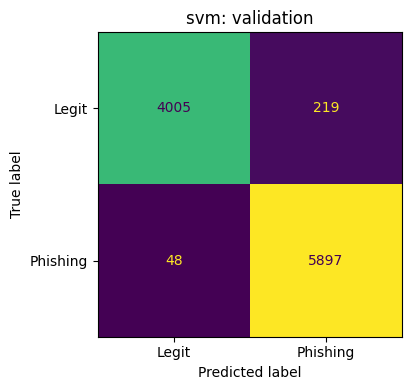

TEST  F1 0.8233 | precision 0.7238 | recall 0.9545 | ROC-AUC 0.9229


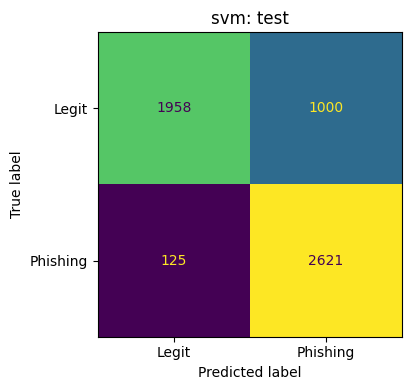

,weight,pushes_toward
subj__com daily,1.779853,phishing
body__love,1.772555,phishing
exclaim_count_log,1.748417,phishing
body__payment,1.288973,phishing
body__kindly,1.261134,phishing
body__responsible,1.248097,phishing
body__remove,1.244651,phishing
body__lose,1.242193,phishing
body__click,1.213077,phishing
body__dear emailtoken,1.187015,phishing


Saved to /content/drive/MyDrive/CYT300/imge/results/svm


In [8]:
run_model('svm',
          LinearSVC(class_weight='balanced', max_iter=5000),
          {'C': [0.05, 0.1, 0.3, 0.5, 1, 2, 5]},
          n_iter=6, calibrate=True)


NB
Fitting 3 folds for each of 5 candidates, totalling 15 fits
Best settings: {'alpha': 0.03} | CV F1 = 0.9606
Train F1 0.9641 | Validation F1 0.9643 | gap -0.0002
              precision    recall  f1-score   support

       Legit     0.9194    0.9889    0.9529      4224
    Phishing     0.9916    0.9384    0.9643      5945

    accuracy                         0.9594     10169
   macro avg     0.9555    0.9637    0.9586     10169
weighted avg     0.9617    0.9594    0.9596     10169



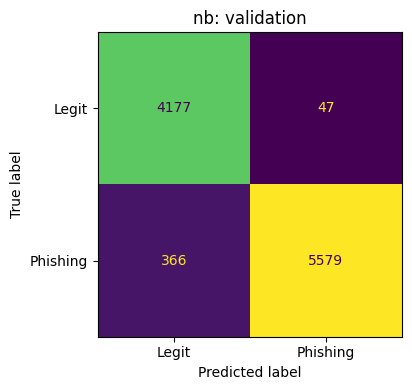

TEST  F1 0.8347 | precision 0.8661 | recall 0.8055 | ROC-AUC 0.9181


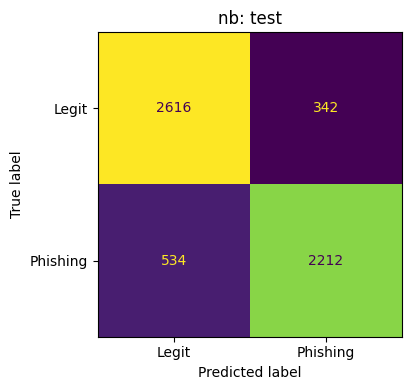

,log_odds,pushes_toward
subj__alerts custom,9.718300,phishing
subj__custom alert,9.718300,phishing
subj__replica,9.433595,phishing
subj__watches,9.267715,phishing
body__custom alert,8.874026,phishing
subj__replica watches,8.778316,phishing
subj__rolex,8.756011,phishing
body__network lp,8.731375,phishing
u_anchor_mismatch,8.593703,phishing
body__watches replica,8.586413,phishing


Saved to /content/drive/MyDrive/CYT300/imge/results/nb


In [9]:
run_model('nb',
          MultinomialNB(),
          {'alpha': [0.01, 0.03, 0.1, 0.3, 1.0]},
          n_iter=5)


RF
Train F1 1.0000 | Validation F1 0.9793 | gap +0.0207
              precision    recall  f1-score   support

       Legit     0.9842    0.9564    0.9701      4224
    Phishing     0.9697    0.9891    0.9793      5945

    accuracy                         0.9755     10169
   macro avg     0.9769    0.9728    0.9747     10169
weighted avg     0.9757    0.9755    0.9755     10169



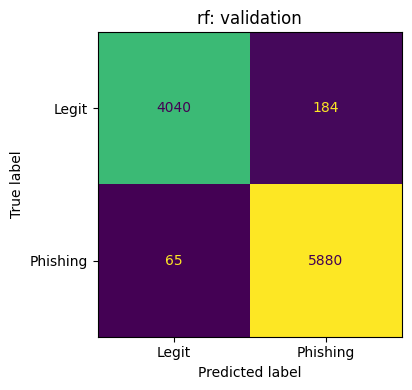

TEST  F1 0.8279 | precision 0.7760 | recall 0.8871 | ROC-AUC 0.9225


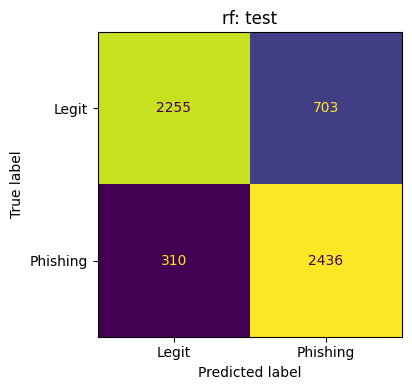

,importance
subject_is_reply,0.042318
body__wrote,0.037030
body_len_log,0.029189
body__emailtoken,0.020408
u_count,0.017585
body__emailtoken urltoken,0.015354
sender_local_len_log,0.011641
subject_len_log,0.011049
upper_ratio,0.010894
body__version,0.010078


Saved to /content/drive/MyDrive/CYT300/imge/results/rf


In [10]:
run_model('rf',
          RandomForestClassifier(n_estimators=200, max_features='sqrt', class_weight='balanced',
                                 n_jobs=-1, random_state=SEED),
          {}, n_iter=1, tune=False)


MLP
Fitting 3 folds for each of 3 candidates, totalling 9 fits
Best settings: {'learning_rate_init': 0.001, 'hidden_layer_sizes': (128,), 'alpha': 0.001} | CV F1 = 0.988
Train F1 0.9984 | Validation F1 0.9800 | gap +0.0184
              precision    recall  f1-score   support

       Legit     0.9926    0.9498    0.9707      4224
    Phishing     0.9654    0.9950    0.9800      5945

    accuracy                         0.9762     10169
   macro avg     0.9790    0.9724    0.9753     10169
weighted avg     0.9767    0.9762    0.9761     10169



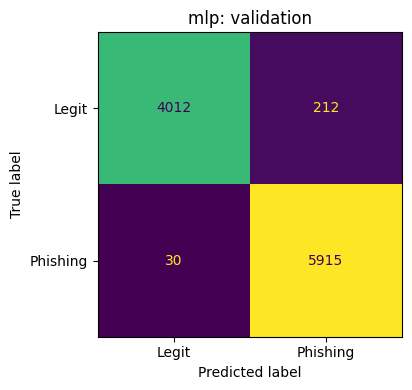

TEST  F1 0.8550 | precision 0.7928 | recall 0.9279 | ROC-AUC 0.9354


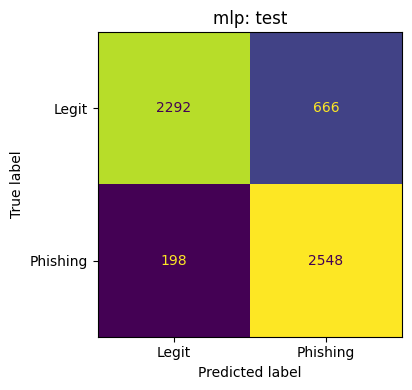

Saved to /content/drive/MyDrive/CYT300/imge/results/mlp


In [11]:
run_model('mlp',
          MLPClassifier(early_stopping=True, validation_fraction=0.1, n_iter_no_change=3,
                        max_iter=30, batch_size=512, random_state=SEED),
          {'hidden_layer_sizes': [(64,), (128,)],
           'alpha': [1e-5, 1e-4, 1e-3],
           'learning_rate_init': [1e-3, 3e-3]},
          n_iter=3)

In [12]:
rows = []
for p in sorted(Path(OUT_DIR).glob('*/metrics.json')):
    m = json.loads(p.read_text())
    s = m['test'] or m['validation']                     # prefer the external test set
    rows.append({'model': m['model'], 'evaluated_on': 'test' if m['test'] else 'validation',
                 'accuracy': s['accuracy'], 'precision': s['precision'], 'recall': s['recall'], 'f1': s['f1'],
                 'roc_auc': s['roc_auc'], 'pr_auc': s['pr_auc'],
                 'false_pos_rate': s['false_positive_rate'], 'false_neg_rate': s['false_negative_rate'],
                 'val_f1': m['validation']['f1'],
                 'train_val_gap': m['train']['f1'] - m['validation']['f1'],
                 'tune_sec': m['tuning_seconds'], 'ms_per_email': m['predict_ms_per_email']})

comparison = pd.DataFrame(rows).set_index('model').sort_values('f1', ascending=False).round(4)
comparison.to_csv(f'{OUT_DIR}/model_comparison.csv')
comparison

,evaluated_on,accuracy,precision,recall,f1,roc_auc,pr_auc,false_pos_rate,false_neg_rate,val_f1,train_val_gap,tune_sec,ms_per_email
model,,,,,,,,,,,,,
mlp,test,0.8485,0.7928,0.9279,0.8550,0.9354,0.9315,0.2252,0.0721,0.9800,0.0184,170.8,0.0106
logreg,test,0.8464,0.7929,0.9217,0.8525,0.9273,0.9208,0.2235,0.0783,0.9771,0.0228,49.2,0.0010
nb,test,0.8464,0.8661,0.8055,0.8347,0.9181,0.9106,0.1156,0.1945,0.9643,-0.0002,6.1,0.0025
rf,test,0.8224,0.7760,0.8871,0.8279,0.9225,0.9193,0.2377,0.1129,0.9793,0.0207,141.8,0.1319
svm,test,0.8028,0.7238,0.9545,0.8233,0.9229,0.9063,0.3381,0.0455,0.9779,0.0208,14.7,0.0091


In [13]:
# ---------- Final model: Logistic Regression, threshold chosen by false-alarm rate ----------
groups_test = np.load(f'{DATA_DIR}/groups_test.npy', allow_pickle=True)   # sender of each test email
rules_test  = np.load(f'{DATA_DIR}/rules_test.npy')                       # did a strong rule fire
final = joblib.load(f'{OUT_DIR}/logreg/model.joblib')
p = final.predict_proba(X_test)[:, 1]                                      # phishing probability per test email

# Split the test set in two by sender: one half picks the threshold, the other half gives the reported numbers
sgkf = StratifiedGroupKFold(n_splits=2, shuffle=True, random_state=SEED)
val_idx, fin_idx = next(sgkf.split(X_test, y_test, groups=groups_test))
yv, yf = y_test[val_idx], y_test[fin_idx]
print(f"threshold half: {len(yv)} emails | reported half: {len(yf)} emails")

def summarize(target, system, pred):
    pred = pred.astype(int)
    return {'target false-alarm rate': f"{target:.0%}", 'system': system,
            'phishing caught (recall)': recall_score(yf, pred),
            'false-alarm rate': ((pred == 1) & (yf == 0)).sum() / (yf == 0).sum(),
            'precision': precision_score(yf, pred, zero_division=0), 'F1': f1_score(yf, pred)}

rows, thresholds = [summarize(0, 'rules only', rules_test[fin_idx])], {}
for target in [0.01, 0.05, 0.10]:
    thr = float(np.quantile(p[val_idx][yv == 0], 1 - target))   # threshold giving that false-alarm rate
    thresholds[target] = thr
    rows.append(summarize(target, 'ML', p[fin_idx] >= thr))
    rows.append(summarize(target, 'ML OR rules', (p[fin_idx] >= thr) | rules_test[fin_idx]))

final_table = pd.DataFrame(rows).round(3)
final_table.to_csv(f'{OUT_DIR}/final_threshold_table.csv', index=False)
print(final_table.to_string(index=False))
print("Thresholds:", {f"{k:.0%}": round(v, 4) for k, v in thresholds.items()})

threshold half: 2970 emails | reported half: 2734 emails
target false-alarm rate      system  phishing caught (recall)  false-alarm rate  precision    F1
                     0%  rules only                     0.162             0.003      0.977 0.278
                     1%          ML                     0.267             0.003      0.989 0.421
                     1% ML OR rules                     0.350             0.006      0.983 0.516
                     5%          ML                     0.635             0.031      0.948 0.760
                     5% ML OR rules                     0.673             0.034      0.947 0.786
                    10%          ML                     0.814             0.093      0.887 0.849
                    10% ML OR rules                     0.836             0.095      0.888 0.861
Thresholds: {'1%': 0.9993, '5%': 0.9861, '10%': 0.9109}


In [14]:
# ---------- Export everything the mail server needs, in one file ----------
import sklearn, sys

TARGET = 0.10                                  # <- your chosen false-alarm rate (0.05 or 0.10)
THRESHOLD = thresholds[TARGET]

deploy_prep = {k: v for k, v in prep.items() if k not in ('train_keys', 'corpus_words')}   # training-only parts removed
bundle = {'model': final, 'threshold': THRESHOLD, 'target_false_alarm_rate': TARGET,
          'prep': deploy_prep, 'model_name': 'logreg',
          'sklearn_version': sklearn.__version__, 'python_version': sys.version.split()[0]}
joblib.dump(bundle, f'{OUT_DIR}/phish_model_bundle.joblib', compress=3)

print(f"Saved bundle | threshold {THRESHOLD:.4f} (target false-alarm rate {TARGET:.0%})")
print("Install EXACTLY these on VM2 -> scikit-learn", sklearn.__version__, "| Python", sys.version.split()[0])

Saved bundle | threshold 0.9109 (target false-alarm rate 10%)
Install EXACTLY these on VM2 -> scikit-learn 1.6.1 | Python 3.13.16


In [15]:
# ---------- Standalone check: load the bundle like the mail server will ----------
from google.colab import drive
drive.mount('/content/drive')
import sys, joblib
sys.path.append('/content/drive/MyDrive/CYT300/imge')
from features import featurize_one

b = joblib.load('/content/drive/MyDrive/CYT300/imge/results/phish_model_bundle.joblib')
print("Loaded:", b['model_name'], "| threshold", round(b['threshold'], 4), "| sklearn", b['sklearn_version'])

tests = [('PayPal Support <support@secure-mail.xyz>', 'user@example.com', 'Your account is suspended',
          'Please verify your account immediately: http://192.168.1.10/login'),
         ('Sarah Lee <sarah.lee@company.com>', 'user@company.com', 'Re: meeting notes',
          'Hi, attached are the notes from Tuesday. Let me know if I missed anything. Thanks, Sarah')]
for sender, rcv, subj, body in tests:
    x, fired = featurize_one(sender, rcv, subj, body, b['prep'])
    score = b['model'].predict_proba(x)[0, 1]
    verdict = 'PHISHING' if score >= b['threshold'] or fired else 'CLEAN'
    print(f"{verdict:8s} | score {score:.3f} | rules fired: {fired} | {subj}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loaded: logreg | threshold 0.9109 | sklearn 1.6.1
PHISHING | score 1.000 | rules fired: ['s_display_brand_mismatch', 'u_ip'] | Your account is suspended
CLEAN    | score 0.002 | rules fired: [] | Re: meeting notes


In [16]:
import numpy, scipy, pandas; print(numpy.__version__, scipy.__version__, pandas.__version__)

2.1.3 1.16.3 2.2.3
